In [4]:
from google.colab import files
uploaded = files.upload()

KeyboardInterrupt: 

In [9]:
import zipfile
import os

zip_name = next(iter(uploaded))

os.makedirs("/content/pork_dataset", exist_ok=True)

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall("/content/pork_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [ ]:
%pip install ultralytics

In [49]:
from ultralytics import YOLO

# Load pretrained YOLOv8n model
model = YOLO("yolov8n.pt")

# Recreate original baseline configuration
model.train(
    data="/content/pork_dataset/data.yaml",
    epochs=10,
    imgsz=640,
    batch=16,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_baseline",
    exist_ok=True
)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pork_baseline, nbs=64, nms=None, opset=None, optimize=Fals

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78f2e7be3700>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
from google.colab import files

files.download(
    "/content/runs/pork_baseline/weights/best.pt"
)

In [ ]:
from ultralytics import YOLO
from IPython.display import display, Image
import glob
import random
import os

# Load your trained model
model = YOLO("/content/runs/pork_baseline/weights/best.pt")

# Find images from the test dataset
images = glob.glob("/content/pork_dataset/test/images/*")

# Select 5 random images
random.seed(42)
selected_images = random.sample(images, min(5, len(images)))

# Predict defects and save annotated images
results = model.predict(
    source=selected_images,
    conf=0.25,
    save=True,
    project="/content/runs",
    name="test_predictions"
)

# Display predictions
for result in results:
    filename = os.path.join(result.save_dir, result.path.split("/")[-1])
    display(Image(filename=filename))

In [ ]:
from pathlib import Path
from collections import Counter

dataset = Path("/content/pork_dataset")

class_names = [
    "loose-meat",
    "packaging-error",
    "twisted-meat",
    "unsealed",
    "wrinkle"
]

for split in ["train", "valid", "test"]:
    counts = Counter()
    invalid = []

    for file in (dataset / split / "labels").glob("*.txt"):
        for line in file.read_text().splitlines():
            parts = line.split()

            if len(parts) != 5:
                invalid.append(file.name)
                continue

            counts[int(parts[0])] += 1

    print(f"\n{split.upper()} SET")

    for i, name in enumerate(class_names):
        print(f"{name}: {counts[i]}")

    print("Files with non-standard labels:", len(set(invalid)))

In [ ]:
from pathlib import Path

labels_dir = Path("/content/pork_dataset/train/labels")

for label_file in labels_dir.glob("*.txt"):
    for line_number, line in enumerate(label_file.read_text().splitlines(), 1):
        parts = line.split()

        if len(parts) != 5:
            print("File:", label_file.name)
            print("Line:", line_number)
            print("Values:", line)
            print("-" * 50)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import glob
import os

# Safely search for any results.csv in the runs directory to handle potential duplicate run folders
results_files = glob.glob("/content/runs/**/results.csv", recursive=True)

if not results_files:
    raise FileNotFoundError("Could not find any 'results.csv' in the /content/runs/ directory. Please ensure training completed successfully.")

# Use the most recently modified or found results.csv
results_path = results_files[-1]
print(f"Loading results from: {results_path}")

results = pd.read_csv(results_path)

# Strip leading and trailing whitespace from column headers to prevent KeyError
results.columns = results.columns.str.strip()

print("Cleaned columns:", results.columns.tolist())

metrics = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

# Filter only the metrics that actually exist in the dataframe
valid_metrics = [m for m in metrics if m in results.columns]

results[valid_metrics].plot(figsize=(10, 5))
plt.xlabel("Epoch")
plt.ylabel("Metric value")
plt.title("YOLOv8 Baseline Validation Performance")
plt.grid(True)
plt.show()

In [43]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

model.train(
    data="/content/pork_dataset/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    patience=12,
    seed=42,
    plots=True,
    project="/content/runs",
    name="pork_50epochs"
)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pork_50epochs, nbs=64, nms=None, opset=None, optimize=Fal

Exception ignored in: <function _afterFork at 0x78f4e9b06ca0>
Traceback (most recent call last):
  File "/usr/lib/python3.13/logging/__init__.py", line 245, in _afterFork
    def _afterFork():
KeyboardInterrupt: 
Exception ignored in: 
<function Socket.__del__ at 0x78f4e8bf8b80>Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/zmq/sugar/socket.py", line 184, in __del__
    def __del__(self):
KeyboardInterrupt: 


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 0/4  5.3s


KeyboardInterrupt: 

In [ ]:
from ultralytics import YOLO

# Load the best weights from the 50-epoch experiment
model_50 = YOLO("/content/runs/pork_50epochs/weights/best.pt")

# Evaluate on the validation dataset
metrics_50 = model_50.val(
    data="/content/pork_dataset/data.yaml",
    split="val",
    project="/content/runs",
    name="pork_50epochs_validation"
)

print("Precision:", metrics_50.box.mp)
print("Recall:", metrics_50.box.mr)
print("mAP@50:", metrics_50.box.map50)
print("mAP@50-95:", metrics_50.box.map)

In [ ]:
from IPython.display import Image, display

display(Image(
    filename="/content/runs/pork_50epochs_validation/confusion_matrix_normalized.png",
    width=800
))

In [ ]:
from IPython.display import Image, display
from pathlib import Path

validation_dir = Path(
    "/content/runs/pork_50epochs_validation"
)

for filename in [
    "val_batch0_pred.jpg",
    "val_batch1_pred.jpg"
]:
    image_path = validation_dir / filename

    if image_path.exists():
        display(Image(filename=str(image_path), width=900))
    else:
        print(f"Not found: {filename}")

In [ ]:
from IPython.display import Image, display

display(Image(
    filename="/content/runs/pork_50epochs_validation/val_batch0_labels.jpg",
    width=1000
))

In [ ]:
from ultralytics import YOLO

# New experiment: higher image resolution
model_800 = YOLO("yolov8n.pt")

model_800.train(
    data="/content/pork_dataset/data.yaml",
    epochs=50,
    imgsz=800,
    batch=16,
    patience=12,
    seed=42,
    project="/content/runs",
    name="pork_800resolution"
)

In [ ]:
from IPython.display import Image, display

display(Image(filename="/content/runs/pork_baseline/results.png"))

In [ ]:
from pathlib import Path

labels_dir = Path("/content/pork_dataset/train/labels")

files_to_fix = [
    "frame_with_red_9524_jpg.rf.132ecddbe1bc37f7626db75a3e46d3be.txt",
    "frame_with_red_10514_jpg.rf.cfeb7147d93a993d2e5efcd8f5703894.txt"
]

for filename in files_to_fix:
    path = labels_dir / filename

    lines = path.read_text().splitlines()
    corrected_lines = []

    for line in lines:
        values = list(map(float, line.split()))

        if len(values) > 5:
            class_id = int(values[0])

            x_coords = values[1::2]
            y_coords = values[2::2]

            x_min = min(x_coords)
            x_max = max(x_coords)
            y_min = min(y_coords)
            y_max = max(y_coords)

            x_center = (x_min + x_max) / 2
            y_center = (y_min + y_max) / 2

            width = x_max - x_min
            height = y_max - y_min

            corrected_line = (
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{width:.6f} {height:.6f}"
            )

            corrected_lines.append(corrected_line)

            print(f"Corrected: {filename}")
            print(f"New annotation: {corrected_line}")

        else:
            corrected_lines.append(line)

    path.write_text("\n".join(corrected_lines) + "\n")

In [ ]:
from pathlib import Path

labels_dir = Path("/content/pork_dataset/train/labels")

invalid_annotations = []

for label_file in labels_dir.glob("*.txt"):
    for line_number, line in enumerate(label_file.read_text().splitlines(), 1):
        parts = line.split()

        if len(parts) != 5:
            invalid_annotations.append(
                (label_file.name, line_number, line)
            )

print(f"Invalid annotation lines: {len(invalid_annotations)}")

if invalid_annotations:
    for item in invalid_annotations:
        print(item)
else:
    print("All training annotations contain 5 values.")

In [ ]:
from pathlib import Path

dataset_dir = Path("/content/pork_dataset")

cache_files = list(dataset_dir.rglob("*.cache"))

for cache_file in cache_files:
    cache_file.unlink()
    print(f"Removed: {cache_file}")

print(f"\nTotal cache files removed: {len(cache_files)}")

In [ ]:
from ultralytics import YOLO

# Initialise a new YOLOv8n model
model_800 = YOLO("yolov8n.pt")

# Train using the corrected dataset
model_800.train(
    data="/content/pork_dataset/data.yaml",
    epochs=50,
    imgsz=800,
    batch=16,
    project="/content/runs",
    name="pork_800resolution",
    seed=42
)

In [ ]:
from IPython.display import Image, display

display(Image(
    filename="/content/runs/pork_800resolution-2/confusion_matrix_normalized.png",
    width=850
))

In [ ]:
from ultralytics import YOLO
from IPython.display import display, Image
from pathlib import Path

model = YOLO(
    "/content/runs/pork_800resolution-2/weights/best.pt"
)

model.predict(
    source="/content/pork_dataset/valid/images",
    imgsz=800,
    conf=0.25,
    save=True,
    project="/content/runs",
    name="pork_800_predictions",
    exist_ok=True
)

prediction_dir = Path("/content/runs/pork_800_predictions")

images = list(prediction_dir.glob("*.jpg"))

for image_path in images[:5]:
    display(Image(filename=str(image_path), width=650))

In [ ]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image

model = YOLO(
    "/content/runs/pork_800resolution-2/weights/best.pt"
)

labels_dir = Path("/content/pork_dataset/valid/labels")
images_dir = Path("/content/pork_dataset/valid/images")

# Find images containing packaging-error (class 1)
packaging_images = []

for label_file in sorted(labels_dir.glob("*.txt")):
    lines = label_file.read_text().splitlines()

    if any(line.split() and line.split()[0] == "1" for line in lines):
        for extension in [".jpg", ".jpeg", ".png"]:
            image_path = images_dir / (label_file.stem + extension)

            if image_path.exists():
                packaging_images.append(image_path)
                break

print(f"Images containing packaging-error: {len(packaging_images)}")

# Predict on five examples
results = model.predict(
    source=[str(p) for p in packaging_images[:5]],
    imgsz=800,
    conf=0.25,
    save=True,
    project="/content/runs",
    name="packaging_error_predictions",
    exist_ok=True
)

for result in results:
    display(Image(data=result.plot()[:, :, ::-1].tobytes(),
                  format="raw")) if False else display(
        Image(filename=str(
            Path("/content/runs/packaging_error_predictions")
            / Path(result.path).name
        ), width=650)
    )

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

# Select the same five packaging-error validation images
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, image_path in zip(axes, packaging_images[:5]):

    img = Image.open(image_path)
    ax.imshow(img)

    width, height = img.size

    label_path = (
        Path("/content/pork_dataset/valid/labels")
        / (image_path.stem + ".txt")
    )

    for line in label_path.read_text().splitlines():
        values = list(map(float, line.split()))

        class_id = int(values[0])
        x, y, w, h = values[1:5]

        x_min = (x - w / 2) * width
        y_min = (y - h / 2) * height

        rect = patches.Rectangle(
            (x_min, y_min),
            w * width,
            h * height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)

        ax.text(
            x_min,
            max(0, y_min - 5),
            model.names[class_id],
            color="red",
            fontsize=9,
            weight="bold"
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from ultralytics import YOLO

model_augmented = YOLO("yolov8n.pt")

model_augmented.train(
    data="/content/pork_dataset/data.yaml",
    epochs=50,
    imgsz=800,
    batch=16,
    project="/content/runs",
    name="pork_augmented",
    seed=42,

    # Moderate geometric augmentation
    degrees=10,
    translate=0.1,
    scale=0.2,

    # Lighting and colour variation
    hsv_h=0.01,
    hsv_s=0.3,
    hsv_v=0.2,

    # Disable mosaic augmentation
    mosaic=0.0
)

In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/pork_augmented/weights/best.pt")

test_results = model.val(
    data="/content/pork_dataset/data.yaml",
    split="test",
    imgsz=800,
    project="/content/runs",
    name="pork_augmented_test"
)

print("Test Precision:", test_results.box.mp)
print("Test Recall:", test_results.box.mr)
print("Test mAP@50:", test_results.box.map50)
print("Test mAP@50-95:", test_results.box.map)

In [ ]:
from google.colab import files

files.download(
    "/content/runs/pork_augmented/weights/best.pt"
)

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch
import time
import numpy as np

test_images = sorted(
    Path("/content/pork_dataset/test/images").glob("*.jpg")
)[:30]

models = {
    "Baseline (640px)": (
        "/content/runs/pork_baseline/weights/best.pt", 640
    ),
    "Augmented (800px)": (
        "/content/runs/pork_augmented/weights/best.pt", 800
    )
}

for name, (weights, resolution) in models.items():

    model = YOLO(weights)

    # GPU warm-up
    for image in test_images[:5]:
        model.predict(
            str(image), imgsz=resolution,
            device=0, verbose=False
        )

    torch.cuda.synchronize()
    start = time.perf_counter()

    for image in test_images:
        model.predict(
            str(image), imgsz=resolution,
            device=0, verbose=False
        )

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    avg_time = elapsed / len(test_images)

    print(f"\n{name}")
    print(f"Total inference time: {elapsed:.3f} seconds")
    print(f"Average time per image: {avg_time*1000:.2f} ms")
    print(f"Throughput: {1/avg_time:.2f} images/second")

In [5]:
from google.colab import files

uploaded = files.upload()

Saving best (2).pt to best (2).pt


In [6]:
from ultralytics import YOLO

model = YOLO("/content/best (2).pt")

print("Model loaded successfully!")
print("Model classes:", model.names)

Model loaded successfully!
Model classes: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed', 4: 'wrinkle'}


In [7]:
from ultralytics import YOLO
from pathlib import Path
import torch
import time

model = YOLO("/content/best (2).pt")

test_images = sorted(
    p for p in Path("/content/pork_dataset/test/images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)[:30]

assert test_images, "No test images found."

# Warm up GPU
for image in test_images[:5]:
    model.predict(str(image), imgsz=800, device=0, verbose=False)

torch.cuda.synchronize()
start = time.perf_counter()

for image in test_images:
    model.predict(str(image), imgsz=800, device=0, verbose=False)

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

print(f"Images processed: {len(test_images)}")
print(f"Total inference time: {elapsed:.3f} seconds")
print(f"Average time per image: {elapsed/len(test_images)*1000:.2f} ms")
print(f"Throughput: {len(test_images)/elapsed:.2f} images/second")

FileNotFoundError: [Errno 2] No such file or directory: '/content/pork_dataset/test/images'

In [8]:
import os

print("Files in /content:")
print(os.listdir("/content"))

print("\nAvailable image folders:")
for root, dirs, files in os.walk("/content"):
    if "images" in dirs:
        print(os.path.join(root, "images"))

Files in /content:
['.config', 'best (2).pt', 'sample_data']

Available image folders:


In [10]:
import os

print(os.listdir("/content/pork_dataset"))

['best']


In [11]:
import os

print(os.listdir("/content/pork_dataset/best"))

['version', '.data', 'data', '.format_version', 'data.pkl', '.storage_alignment', 'byteorder']


In [14]:
from google.colab import files

uploaded = files.upload()

Saving Pork Rasher Error-Packaging-.v1i.yolov8 (1).zip to Pork Rasher Error-Packaging-.v1i.yolov8 (1).zip


In [15]:
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith(".zip") or file == "data.yaml":
            print(os.path.join(root, file))

/content/Pork Rasher Error-Packaging-.v1i.yolov8 (1).zip


In [16]:
import zipfile
import os

zip_path = "/content/Pork Rasher Error-Packaging-.v1i.yolov8 (1).zip"
extract_path = "/content/pork_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Contents:", os.listdir(extract_path))

Dataset extracted successfully!
Contents: ['train', 'best', 'valid', 'data.yaml', 'README.roboflow.txt', 'test']


In [17]:
from ultralytics import YOLO
from pathlib import Path
import torch
import time

# Load previously trained augmented model
model = YOLO("/content/best (2).pt")

# Select 30 test images
test_images = sorted(
    p for p in Path("/content/pork_dataset/test/images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)[:30]

assert test_images, "No test images found."

# Warm up GPU
for image in test_images[:5]:
    model.predict(str(image), imgsz=800, device=0, verbose=False)

# Benchmark inference
torch.cuda.synchronize()
start = time.perf_counter()

for image in test_images:
    model.predict(str(image), imgsz=800, device=0, verbose=False)

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

print(f"Images processed: {len(test_images)}")
print(f"Total inference time: {elapsed:.3f} seconds")
print(f"Average inference time: {elapsed/len(test_images)*1000:.2f} ms")
print(f"Throughput: {len(test_images)/elapsed:.2f} images/second")

Images processed: 30
Total inference time: 0.347 seconds
Average inference time: 11.57 ms
Throughput: 86.41 images/second


In [18]:
from ultralytics import YOLO
import torch
import time

model = YOLO("/content/best (2).pt")

# Use the same 30 test images as before
for image in test_images[:5]:
    model.predict(
        str(image),
        imgsz=640,
        device=0,
        verbose=False
    )

torch.cuda.synchronize()
start = time.perf_counter()

for image in test_images:
    model.predict(
        str(image),
        imgsz=640,
        device=0,
        verbose=False
    )

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

print(f"Images processed: {len(test_images)}")
print(f"Total inference time: {elapsed:.3f} seconds")
print(f"Average inference time: {elapsed/len(test_images)*1000:.2f} ms")
print(f"Throughput: {len(test_images)/elapsed:.2f} images/second")

Images processed: 30
Total inference time: 0.343 seconds
Average inference time: 11.42 ms
Throughput: 87.55 images/second


In [19]:
from ultralytics import YOLO

model = YOLO("/content/best (2).pt")

results_640 = model.val(
    data="/content/pork_dataset/data.yaml",
    split="test",
    imgsz=640,
    device=0,
    project="/content/runs",
    name="pork_640_inference_test"
)

print("\n640px Test Results")
print(f"Precision: {results_640.box.mp:.4f}")
print(f"Recall: {results_640.box.mr:.4f}")
print(f"mAP@50: {results_640.box.map50:.4f}")
print(f"mAP@50-95: {results_640.box.map:.4f}")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1815.7±469.7 MB/s, size: 51.2 KB)
val: Scanning /content/pork_dataset/test/labels... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 892.3it/s 0.1s
val: New cache created: /content/pork_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.9it/s 1.7s
                   all         76         91      0.337      0.542      0.425      0.173
            loose-meat          2          3      0.197      0.333      0.199     0.0881
       packaging-error         22         29      0.412      0.655      0.439      0.098
          twisted-meat          7          7       0.24      0.429      0.366      0.135
              unsealed         51         52      0.499       0.75      0.697  

In [20]:
from ultralytics import YOLO

model = YOLO("/content/best (2).pt")

results_800 = model.val(
    data="/content/pork_dataset/data.yaml",
    split="test",
    imgsz=800,
    device=0,
    project="/content/runs",
    name="pork_800_inference_test"
)

print("\n640px Test Results")
print(f"Precision: {results_800.box.mp:.4f}")
print(f"Recall: {results_800.box.mr:.4f}")
print(f"mAP@50: {results_800.box.map50:.4f}")
print(f"mAP@50-95: {results_800.box.map:.4f}")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2025.5±727.3 MB/s, size: 50.5 KB)
val: Scanning /content/pork_dataset/test/labels.cache... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 26.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.5it/s 2.0s
                   all         76         91      0.502      0.547      0.475      0.181
            loose-meat          2          3      0.443      0.295      0.275      0.103
       packaging-error         22         29      0.484      0.389      0.495      0.114
          twisted-meat          7          7      0.379      0.714      0.411      0.127
              unsealed         51         52        0.7      0.788      0.721      0.379
Speed: 4.7ms preprocess, 4.2ms inference, 0.0ms 

In [21]:
from ultralytics import YOLO
from pathlib import Path
import torch
import time
import numpy as np

# Load your final augmented model
model = YOLO("/content/best (2).pt")

# Select the same 30 test images
test_images = sorted(
    p for p in Path("/content/pork_dataset/test/images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)[:30]

for resolution in [640, 800]:
    timings = []

    # GPU warm-up
    for _ in range(10):
        model.predict(
            str(test_images[0]),
            imgsz=resolution,
            device=0,
            verbose=False
        )

    # Repeat benchmark 5 times
    for repeat in range(5):
        torch.cuda.synchronize()
        start = time.perf_counter()

        for image in test_images:
            model.predict(
                str(image),
                imgsz=resolution,
                device=0,
                verbose=False
            )

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        timings.append(elapsed / len(test_images) * 1000)

    print(f"\nResolution: {resolution}px")
    print(f"Mean inference time: {np.mean(timings):.2f} ms/image")
    print(f"Standard deviation: {np.std(timings, ddof=1):.2f} ms")
    print(f"Mean throughput: {1000 / np.mean(timings):.2f} images/s")


Resolution: 640px
Mean inference time: 11.33 ms/image
Standard deviation: 0.74 ms
Mean throughput: 88.25 images/s

Resolution: 800px
Mean inference time: 12.45 ms/image
Standard deviation: 0.90 ms
Mean throughput: 80.31 images/s


In [22]:
from ultralytics import YOLO

model = YOLO("/content/best (2).pt")

thresholds = [0.05, 0.10, 0.25, 0.40, 0.60]

for conf in thresholds:
    results = model.val(
        data="/content/pork_dataset/data.yaml",
        split="val",
        imgsz=800,
        conf=conf,
        device=0,
        plots=False,
        verbose=False
    )

    print(f"\nConfidence threshold: {conf}")
    print(f"Precision: {results.box.mp:.4f}")
    print(f"Recall: {results.box.mr:.4f}")
    print(f"mAP@50: {results.box.map50:.4f}")
    print(f"mAP@50-95: {results.box.map:.4f}")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1862.0±520.7 MB/s, size: 51.5 KB)
val: Scanning /content/pork_dataset/valid/labels... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 1.4Kit/s 0.1s
val: New cache created: /content/pork_dataset/valid/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 6.5it/s 1.2s
                   all        115        143        0.7      0.599      0.638       0.34
Speed: 1.1ms preprocess, 3.7ms inference, 0.0ms loss, 0.9ms postprocess per image

Confidence threshold: 0.05
Precision: 0.6998
Recall: 0.5988
mAP@50: 0.6384
mAP@50-95: 0.3402
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
v

In [23]:
from google.colab import drive
import os
import shutil

# Mount Google Drive
drive.mount("/content/drive")

# Create a permanent project folder
project_dir = "/content/drive/MyDrive/MMA3001_Project"
os.makedirs(project_dir, exist_ok=True)

# Save your final augmented model
shutil.copy2(
    "/content/best (2).pt",
    os.path.join(project_dir, "yolov8_augmented_best.pt")
)

# Save your original dataset ZIP
shutil.copy2(
    "/content/Pork Rasher Error-Packaging-.v1i.yolov8 (1).zip",
    os.path.join(project_dir, "pork_dataset.zip")
)

print("Project files successfully backed up to Google Drive!")
print("Saved files:", os.listdir(project_dir))

Mounted at /content/drive
Project files successfully backed up to Google Drive!
Saved files: ['yolov8_augmented_best.pt', 'pork_dataset.zip']


In [24]:
from ultralytics import YOLO

# Initialise from the same pretrained YOLOv8n weights
model_lr = YOLO("yolov8n.pt")

# Train with a specified learning rate
model_lr.train(
    data="/content/pork_dataset/data.yaml",
    epochs=50,
    imgsz=800,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    seed=42,
    degrees=10,
    translate=0.1,
    scale=0.2,
    hsv_h=0.01,
    hsv_s=0.3,
    hsv_v=0.2,
    mosaic=0.0,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_lr_0_001"
)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_dataset/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.2, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=pork_lr_0_001, nbs=64, nms=None, opset=None, optimize=Fals

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78f32856ba80>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [25]:
from ultralytics import YOLO

# Load the trained AdamW model
model_adamw = YOLO(
    "/content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_001/weights/best.pt"
)

# Evaluate using the validation dataset
results = model_adamw.val(
    data="/content/pork_dataset/data.yaml",
    split="val",
    imgsz=800,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_lr_0_001_validation"
)

# Display overall performance
print("\nAdamW Model Validation Results")
print(f"Precision: {results.box.mp:.4f}")
print(f"Recall: {results.box.mr:.4f}")
print(f"mAP@50: {results.box.map50:.4f}")
print(f"mAP@50-95: {results.box.map:.4f}")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2129.1±818.2 MB/s, size: 50.8 KB)
val: Scanning /content/pork_dataset/valid/labels.cache... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 40.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.3it/s 2.4s
                   all        115        143      0.807      0.601      0.726      0.371
            loose-meat          5          5       0.93        0.6      0.819      0.384
       packaging-error         30         45      0.574     0.0889      0.254     0.0759
          twisted-meat          4          5      0.831          1      0.995      0.536
              unsealed         85         88      0.895      0.716      0.835      0.489
Speed: 3.4ms preprocess, 3.1ms inference, 0.

In [26]:
from ultralytics import YOLO

# Initialise the same pretrained YOLOv8n model
model_lr_low = YOLO("yolov8n.pt")

# Train with a lower learning rate
model_lr_low.train(
    data="/content/pork_dataset/data.yaml",
    epochs=50,
    imgsz=800,
    batch=16,
    optimizer="AdamW",
    lr0=0.0001,
    seed=42,
    degrees=10,
    translate=0.1,
    scale=0.2,
    hsv_h=0.01,
    hsv_s=0.3,
    hsv_v=0.2,
    mosaic=0.0,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_lr_0_0001"
)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_dataset/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.2, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=pork_lr_0_0001, nbs=64, nms=None, opset=None, optimize=Fa

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78f2d41452b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0

In [27]:
import pandas as pd
from pathlib import Path

# Locate the training results for learning rate = 0.0001
project_dir = Path("/content/drive/MyDrive/MMA3001_Project/runs")

runs = sorted(
    project_dir.glob("pork_lr_0_0001*/results.csv"),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not runs:
    print("No results.csv found. Available runs:")
    for folder in project_dir.iterdir():
        if folder.is_dir():
            print(" -", folder.name)
else:
    results_path = runs[0]
    df = pd.read_csv(results_path)
    df.columns = df.columns.str.strip()

    metrics = [
        "metrics/precision(B)",
        "metrics/recall(B)",
        "metrics/mAP50(B)",
        "metrics/mAP50-95(B)"
    ]

    # Best epoch according to mAP@50-95
    best_idx = df["metrics/mAP50-95(B)"].idxmax()
    best = df.loc[best_idx]

    print("MODEL: YOLOv8n")
    print("LEARNING RATE: 0.0001")
    print("RESULTS FILE:", results_path)
    print("BEST EPOCH:", int(best["epoch"]))

    print("\nBEST VALIDATION METRICS")
    print("-" * 35)
    print(f"Precision:   {best[metrics[0]]:.4f}")
    print(f"Recall:      {best[metrics[1]]:.4f}")
    print(f"mAP@50:      {best[metrics[2]]:.4f}")
    print(f"mAP@50-95:   {best[metrics[3]]:.4f}")

    print("\nFINAL EPOCH METRICS")
    print("-" * 35)
    final = df.iloc[-1]
    for metric in metrics:
        print(f"{metric}: {final[metric]:.4f}")

MODEL: YOLOv8n
LEARNING RATE: 0.0001
RESULTS FILE: /content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0001/results.csv
BEST EPOCH: 45

BEST VALIDATION METRICS
-----------------------------------
Precision:   0.8066
Recall:      0.6801
mAP@50:      0.7391
mAP@50-95:   0.3810

FINAL EPOCH METRICS
-----------------------------------
metrics/precision(B): 0.6138
metrics/recall(B): 0.7544
metrics/mAP50(B): 0.6975
metrics/mAP50-95(B): 0.3567


In [28]:
from ultralytics import YOLO

# Load best model from LR = 0.0001 training
model_lr_low = YOLO(
    "/content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0001/weights/best.pt"
)

# Evaluate on validation dataset
results = model_lr_low.val(
    data="/content/pork_dataset/data.yaml",
    split="val",
    imgsz=800,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_lr_0_0001_validation"
)

print("\nLR = 0.0001 — BEST CHECKPOINT")
print(f"Precision: {results.box.mp:.4f}")
print(f"Recall: {results.box.mr:.4f}")
print(f"mAP@50: {results.box.map50:.4f}")
print(f"mAP@50-95: {results.box.map:.4f}")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2081.4±641.7 MB/s, size: 50.8 KB)
val: Scanning /content/pork_dataset/valid/labels.cache... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 37.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.3it/s 2.4s
                   all        115        143      0.807      0.668       0.74      0.381
            loose-meat          5          5      0.813      0.879      0.829      0.443
       packaging-error         30         45      0.581      0.111      0.291     0.0989
          twisted-meat          4          5          1      0.941      0.995      0.489
              unsealed         85         88      0.834      0.741      0.843      0.494
Speed: 3.3ms preprocess, 3.1ms inference, 0.

In [29]:
from ultralytics import YOLO
import time

# Initialise the pretrained YOLOv8n model
model_lr_mid = YOLO("yolov8n.pt")

# Start timing
start_time = time.perf_counter()

# Train using AdamW with learning rate = 0.0003
model_lr_mid.train(
    data="/content/pork_dataset/data.yaml",
    epochs=50,
    imgsz=800,
    batch=16,
    optimizer="AdamW",
    lr0=0.0003,
    seed=42,
    degrees=10,
    translate=0.1,
    scale=0.2,
    hsv_h=0.01,
    hsv_s=0.3,
    hsv_v=0.2,
    mosaic=0.0,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_lr_0_0003"
)

# Stop timing
end_time = time.perf_counter()

print("\nTRAINING PERFORMANCE")
print("-" * 40)
print(f"Total training time: {end_time - start_time:.2f} seconds")
print(f"Total training time: {(end_time - start_time)/60:.2f} minutes")

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pork_dataset/data.yaml, degrees=10, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.2, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=pork_lr_0_0003, nbs=64, nms=None, opset=None, optimize=Fa

In [30]:
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops
from pathlib import Path
import torch
import time
import pandas as pd
import numpy as np

# -------------------------------------------------
# 1. Model checkpoints
# -------------------------------------------------

base = Path("/content/drive/MyDrive/MMA3001_Project/runs")

models = {
    "AdamW LR=0.001": base / "pork_lr_0_001/weights/best.pt",
    "AdamW LR=0.0003": base / "pork_lr_0_0003/weights/best.pt",
    "AdamW LR=0.0001": base / "pork_lr_0_0001/weights/best.pt"
}

# -------------------------------------------------
# 2. Test images
# -------------------------------------------------

image_dir = Path("/content/pork_dataset/test/images")

images = sorted(
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)[:30]

assert len(images) == 30, "Expected at least 30 test images"
assert torch.cuda.is_available(), "Please select a GPU runtime"

device = "cuda:0"
image_paths = [str(p) for p in images]

# -------------------------------------------------
# 3. Profiling
# -------------------------------------------------

results = []

for name, checkpoint in models.items():

    print(f"\nProfiling {name}...")

    model = YOLO(str(checkpoint))

    parameters = sum(
        p.numel() for p in model.model.parameters()
    )

    gflops = get_flops(model.model, imgsz=800)

    # Warm-up GPU and initialise prediction pipeline
    for _ in range(5):
        model.predict(
            source=image_paths[0],
            imgsz=800,
            device=0,
            verbose=False,
            save=False
        )

    torch.cuda.synchronize()

    times = []
    torch.cuda.reset_peak_memory_stats()

    # Time complete sequential prediction passes
    for repeat in range(5):

        torch.cuda.synchronize()
        start = time.perf_counter()

        for image in image_paths:
            model.predict(
                source=image,
                imgsz=800,
                device=0,
                verbose=False,
                save=False
            )

        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        times.append(elapsed)

    # Average over 5 repeats
    mean_time = np.mean(times)

    latency_ms = mean_time / len(images) * 1000
    throughput = len(images) / mean_time

    peak_memory_mb = (
        torch.cuda.max_memory_allocated() / 1024**2
    )

    results.append({
        "Model": name,
        "Parameters": parameters,
        "GFLOPs": round(gflops, 3),
        "Latency (ms/image)": round(latency_ms, 3),
        "Throughput (images/s)": round(throughput, 2),
        "Peak GPU memory (MB)": round(peak_memory_mb, 2)
    })

# -------------------------------------------------
# 4. Display and save results
# -------------------------------------------------

df = pd.DataFrame(results)

print("\nCOMPUTATIONAL PROFILING RESULTS")
print("=" * 80)
print(df.to_string(index=False))

output = base / "learning_rate_profiling.csv"
df.to_csv(output, index=False)

print(f"\nResults saved to: {output}")


Profiling AdamW LR=0.001...

Profiling AdamW LR=0.0003...

Profiling AdamW LR=0.0001...

COMPUTATIONAL PROFILING RESULTS
          Model  Parameters  GFLOPs  Latency (ms/image)  Throughput (images/s)  Peak GPU memory (MB)
 AdamW LR=0.001     3138975  13.679              11.796                  84.77                212.51
AdamW LR=0.0003     3138975  13.679              11.888                  84.12                224.04
AdamW LR=0.0001     3138975  13.679              11.823                  84.58                235.86

Results saved to: /content/drive/MyDrive/MMA3001_Project/runs/learning_rate_profiling.csv


In [31]:
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops
import pandas as pd

# Load selected best-performing checkpoint
model = YOLO(
    "/content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0001/weights/best.pt"
)

network = model.model

# Count model parameters
parameters = sum(p.numel() for p in network.parameters())

# Calculate GFLOPs at different image resolutions
gflops_640 = get_flops(network, imgsz=640)
gflops_800 = get_flops(network, imgsz=800)

results = pd.DataFrame({
    "Resolution": ["640 x 640", "800 x 800"],
    "Parameters": [parameters, parameters],
    "GFLOPs": [gflops_640, gflops_800]
})

print("\nMODEL COMPUTATIONAL COMPLEXITY")
print("=" * 50)
print(results.to_string(index=False))

print("\nCOMPUTATIONAL SCALING")
print("=" * 50)
print(f"GFLOPs ratio (800 / 640): {gflops_800 / gflops_640:.4f}")
print(f"Percentage increase: {(gflops_800 / gflops_640 - 1) * 100:.2f}%")


MODEL COMPUTATIONAL COMPLEXITY
Resolution  Parameters    GFLOPs
 640 x 640     3138975  8.754291
 800 x 800     3138975 13.678580

COMPUTATIONAL SCALING
GFLOPs ratio (800 / 640): 1.5625
Percentage increase: 56.25%


In [32]:
import torch
import pandas as pd
from ultralytics import YOLO
from ultralytics.utils.torch_utils import get_flops

# Load best-performing model
model = YOLO(
    "/content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0001/weights/best.pt"
)

network = model.model.cuda().eval()

# Calculate bytes occupied by tensors
def tensor_bytes(obj):
    if isinstance(obj, torch.Tensor):
        return obj.numel() * obj.element_size()

    elif isinstance(obj, (list, tuple)):
        return sum(tensor_bytes(x) for x in obj)

    elif isinstance(obj, dict):
        return sum(tensor_bytes(x) for x in obj.values())

    return 0


def estimate_memory_traffic(imgsz):

    total_bytes = [0]
    hooks = []

    def memory_hook(module, inputs, outputs):

        input_bytes = tensor_bytes(inputs)
        output_bytes = tensor_bytes(outputs)

        weight_bytes = sum(
            p.numel() * p.element_size()
            for p in module.parameters(recurse=False)
        )

        total_bytes[0] += (
            input_bytes + output_bytes + weight_bytes
        )

    # Register hooks on leaf modules only
    for module in network.modules():
        if len(list(module.children())) == 0:
            hooks.append(
                module.register_forward_hook(memory_hook)
            )

    # Run a forward pass
    with torch.inference_mode():
        dummy = torch.zeros(
            1, 3, imgsz, imgsz,
            device="cuda"
        )
        network(dummy)

    # Remove hooks
    for hook in hooks:
        hook.remove()

    return total_bytes[0]


results = []

for resolution in [640, 800]:

    gflops = get_flops(
        network,
        imgsz=resolution
    )

    memory_bytes = estimate_memory_traffic(
        resolution
    )

    arithmetic_intensity = (
        gflops * 1e9 / memory_bytes
    )

    results.append({
        "Resolution": f"{resolution} x {resolution}",
        "GFLOPs": round(gflops, 3),
        "Estimated traffic (GB)": round(memory_bytes / 1e9, 3),
        "Arithmetic intensity (FLOPs/byte)": round(arithmetic_intensity, 3)
    })

df = pd.DataFrame(results)

print("\nESTIMATED ARITHMETIC INTENSITY")
print("=" * 80)
print(df.to_string(index=False))


ESTIMATED ARITHMETIC INTENSITY
Resolution  GFLOPs  Estimated traffic (GB)  Arithmetic intensity (FLOPs/byte)
 640 x 640   8.754                   0.401                              21.85
 800 x 800  13.679                   0.619                              22.10


In [33]:
import torch
from torch.profiler import profile, ProfilerActivity
from ultralytics import YOLO
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# 1. Load selected YOLOv8 checkpoint
# --------------------------------------------------

checkpoint = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001/weights/best.pt"
)

model = YOLO(checkpoint)
network = model.model.to("cuda").eval()

# --------------------------------------------------
# 2. Create representative input
# --------------------------------------------------

# Batch size 1, RGB image, 800 x 800
dummy_input = torch.randn(
    1, 3, 800, 800,
    device="cuda"
)

# --------------------------------------------------
# 3. Warm up GPU
# --------------------------------------------------

with torch.inference_mode():
    for _ in range(10):
        network(dummy_input)

torch.cuda.synchronize()

# --------------------------------------------------
# 4. Profile forward passes
# --------------------------------------------------

with profile(
    activities=[
        ProfilerActivity.CPU,
        ProfilerActivity.CUDA
    ],
    record_shapes=True,
    profile_memory=True,
    with_stack=False
) as prof:

    with torch.inference_mode():
        for _ in range(10):
            network(dummy_input)

    torch.cuda.synchronize()

# --------------------------------------------------
# 5. Display profiling results
# --------------------------------------------------

print("\nTOP OPERATIONS BY CUDA EXECUTION TIME")
print("=" * 90)

print(
    prof.key_averages().table(
        sort_by="self_cuda_time_total",
        row_limit=20
    )
)

print("\nTOP OPERATIONS BY CUDA MEMORY ALLOCATION")
print("=" * 90)

print(
    prof.key_averages().table(
        sort_by="self_cuda_memory_usage",
        row_limit=15
    )
)

# --------------------------------------------------
# 6. Save profiling results
# --------------------------------------------------

output_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/profiling"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Save raw profiling data as a Chrome trace
prof.export_chrome_trace(
    str(output_dir / "yolov8n_profiler_trace.json")
)

# Save operation-level summary as CSV
records = []

for event in prof.key_averages():
    records.append({
        "Operation": event.key,
        "Calls": event.count,
        "CPU time (us)": event.self_cpu_time_total,
        "CUDA time (us)": event.self_device_time_total,
        "CUDA memory (bytes)": event.self_device_memory_usage
    })

df = pd.DataFrame(records)

df = df.sort_values(
    "CUDA time (us)",
    ascending=False
)

csv_path = output_dir / "yolov8n_profiler_summary.csv"

df.to_csv(csv_path, index=False)

print("\nPROFILING FILES SAVED")
print("=" * 60)
print(f"Summary: {csv_path}")
print(f"Trace: {output_dir / 'yolov8n_profiler_trace.json'}")

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(



TOP OPERATIONS BY CUDA EXECUTION TIME
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                aten::cudnn_convolution        24.01%      30.190ms        35.16%      44.218ms      69.090us      14.506ms        67.92%      14.568ms      22.763us           0 B  

In [34]:
!pip install --quiet line_profiler
%load_ext line_profiler

import torch
from ultralytics import YOLO
from pathlib import Path

# Load selected model
model = YOLO(
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001/weights/best.pt"
)

image_paths = sorted(
    str(p) for p in Path("/content/pork_dataset/test/images").glob("*.jpg")
)[:30]

# Warm up prediction pipeline
for image in image_paths[:5]:
    model.predict(image, imgsz=800, device=0, verbose=False)

def profile_predictions():
    for image in image_paths:
        results = model.predict(
            image,
            imgsz=800,
            device=0,
            verbose=False,
            save=False
        )
        torch.cuda.synchronize()

%lprun -f profile_predictions profile_predictions()

In [35]:
!pip install -q scalene

In [36]:
%%writefile /content/profile_yolov8_scalene.py

import torch
from ultralytics import YOLO
from pathlib import Path
import time

# --------------------------------------------------
# 1. Load best-performing model
# --------------------------------------------------

checkpoint = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001/weights/best.pt"
)

model = YOLO(checkpoint)

# --------------------------------------------------
# 2. Load test images
# --------------------------------------------------

image_dir = Path("/content/pork_dataset/test/images")

images = sorted(
    str(p) for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)[:30]

assert len(images) > 0, "No test images found"
assert torch.cuda.is_available(), "Please enable a GPU runtime"

print("GPU:", torch.cuda.get_device_name(0))
print("Images:", len(images))

# --------------------------------------------------
# 3. Warm up model
# --------------------------------------------------

for _ in range(5):
    model.predict(
        images[0],
        imgsz=800,
        device=0,
        verbose=False,
        save=False
    )

torch.cuda.synchronize()

# --------------------------------------------------
# 4. Repeated inference workload
# --------------------------------------------------

repetitions = 50
total_images = len(images) * repetitions

start_time = time.perf_counter()

for repeat in range(repetitions):

    for image in images:

        model.predict(
            image,
            imgsz=800,
            device=0,
            verbose=False,
            save=False
        )

    torch.cuda.synchronize()

elapsed = time.perf_counter() - start_time

print("\nSCALENE PROFILING WORKLOAD")
print("-" * 45)
print(f"Images processed: {total_images}")
print(f"Total execution time: {elapsed:.2f} seconds")
print(f"Average latency: {elapsed / total_images * 1000:.3f} ms/image")
print(f"Throughput: {total_images / elapsed:.2f} images/s")

Writing /content/profile_yolov8_scalene.py


In [41]:
!python -m scalene run \
    --cpu-only \
    --outfile /content/drive/MyDrive/MMA3001_Project/profiling/scalene_cpu_report.json \
    /content/profile_yolov8_scalene.py

I0000 00:00:1792897767.299558   83803 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792897768.987261   83803 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792897773.602953   83840 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792897775.257627   83840 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point ro

In [38]:
from IPython.display import display, HTML
from pathlib import Path

report_path = Path(
    "/content/drive/MyDrive/MMA3001_Project/profiling/scalene_report.html"
)

if report_path.exists():
    display(HTML(report_path.read_text()))
else:
    print("Scalene report not found.")

Scalene report not found.


In [42]:
!pip install -q line_profiler

import torch
import time
from pathlib import Path
from ultralytics import YOLO
from line_profiler import LineProfiler

# 1. Load optimised model
model = YOLO(
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001/weights/best.pt"
)

# 2. Collect 30 test images
image_dir = Path("/content/pork_dataset/test/images")

images = sorted(
    str(p) for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)[:30]

assert len(images) > 0, "No test images found"
assert torch.cuda.is_available(), "GPU runtime required"

print("GPU:", torch.cuda.get_device_name(0))
print("Images:", len(images))

# 3. Warm up the GPU
for _ in range(5):
    model.predict(
        images[0],
        imgsz=800,
        device=0,
        verbose=False
    )

torch.cuda.synchronize()

# 4. Define the function to profile
def run_inference():

    start = time.perf_counter()

    for image in images:

        results = model.predict(
            image,
            imgsz=800,
            device=0,
            verbose=False,
            save=False
        )

        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    print(f"Total time: {elapsed:.3f} seconds")
    print(f"Average latency: {elapsed / len(images) * 1000:.3f} ms/image")
    print(f"Throughput: {len(images) / elapsed:.2f} images/s")


# 5. Run Line Profiler
profiler = LineProfiler()
profiler.add_function(run_inference)

profiler.enable_by_count()
run_inference()
profiler.disable_by_count()

# 6. Display results
profiler.print_stats()

# 7. Save profiling report
output_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "profiling/line_profiler_results.txt"
)

Path(output_path).parent.mkdir(parents=True, exist_ok=True)

with open(output_path, "w") as f:
    profiler.print_stats(stream=f)

print("\nReport saved to:", output_path)

GPU: NVIDIA L4
Images: 30
Total time: 0.579 seconds
Average latency: 19.309 ms/image
Throughput: 51.79 images/s
Timer unit: 1e-09 s

Total time: 0.579286 s
File: /tmp/ipykernel_8255/451622354.py
Function: run_inference at line 41

Line #      Hits         Time  Per Hit   % Time  Line Contents
    41                                           def run_inference():
    42                                           
    43         1       1992.0   1992.0      0.0      start = time.perf_counter()
    44                                           
    45        31      43168.0   1392.5      0.0      for image in images:
    46                                           
    47        60  576610729.0 9.61e+06     99.5          results = model.predict(
    48        30      13430.0    447.7      0.0              image,
    49        30      14301.0    476.7      0.0              imgsz=800,
    50        30      11288.0    376.3      0.0              device=0,
    51        30      12498.0    416.6

In [44]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Load selected optimised model
# --------------------------------------------------

model_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001/weights/best.pt"
)

assert Path(model_path).exists(), "Model checkpoint not found."

model = YOLO(model_path)

# --------------------------------------------------
# 2. Evaluate on TEST dataset
# --------------------------------------------------

results = model.val(
    data="/content/pork_dataset/data.yaml",
    split="test",
    imgsz=800,
    batch=16,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_lr_0_0001_test",
    exist_ok=True
)

# --------------------------------------------------
# 3. Display overall performance metrics
# --------------------------------------------------

print("\n" + "=" * 55)
print("FINAL OPTIMISED MODEL — TEST RESULTS")
print("=" * 55)

print(f"Precision:    {results.box.mp:.4f}")
print(f"Recall:       {results.box.mr:.4f}")
print(f"mAP@50:       {results.box.map50:.4f}")
print(f"mAP@50-95:    {results.box.map:.4f}")

# --------------------------------------------------
# 4. Display per-class performance (corrected)
# --------------------------------------------------

print("\nPER-CLASS PERFORMANCE")
print("-" * 55)

class_results = []

for index, class_id in enumerate(results.box.ap_class_index):

    precision, recall, ap50, ap5095 = results.box.class_result(index)

    class_results.append({
        "Class": model.names[int(class_id)],
        "Precision": precision,
        "Recall": recall,
        "mAP@50": ap50,
        "mAP@50-95": ap5095
    })

df = pd.DataFrame(class_results)
display(df)

output_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001_test/per_class_metrics.csv"
)

df.to_csv(output_path, index=False)

print("\nPer-class results saved to:", output_path)

# --------------------------------------------------
# 5. Save per-class metrics
# --------------------------------------------------

output_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001_test/per_class_metrics.csv"
)

df.to_csv(output_path, index=False)

print("\nPer-class results saved to:", output_path)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2065.0±607.8 MB/s, size: 49.8 KB)
val: Scanning /content/pork_dataset/test/labels.cache... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 18.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.5it/s 2.0s
                   all         76         91      0.507       0.58      0.537      0.214
            loose-meat          2          3      0.634      0.667      0.607      0.166
       packaging-error         22         29      0.361      0.292      0.335     0.0732
          twisted-meat          7          7      0.377      0.571      0.444      0.177
              unsealed         51         52      0.657      0.788      0.762      0.441
Speed: 3.4ms preprocess, 4.2ms inference, 0.0ms 

,Class,Precision,Recall,mAP@50,mAP@50-95
0,loose-meat,0.633553,0.666667,0.607105,0.165719
1,packaging-error,0.360581,0.292047,0.335271,0.073159
2,twisted-meat,0.377006,0.571429,0.443548,0.176674
3,unsealed,0.657007,0.788462,0.762367,0.441483



Per-class results saved to: /content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0001_test/per_class_metrics.csv

Per-class results saved to: /content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0001_test/per_class_metrics.csv


Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1698.8±541.4 MB/s, size: 49.9 KB)
val: Scanning /content/pork_dataset/valid/labels.cache... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 34.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.1it/s 2.6s
                   all        115        143      0.807      0.668       0.74      0.381
            loose-meat          5          5      0.813      0.879      0.829      0.443
       packaging-error         30         45      0.581      0.111      0.291     0.0989
          twisted-meat          4          5          1      0.941      0.995      0.489
              unsealed         85         88      0.834      0.741      0.843      0.494
Speed: 3.4ms preprocess, 3.1ms inference, 0.

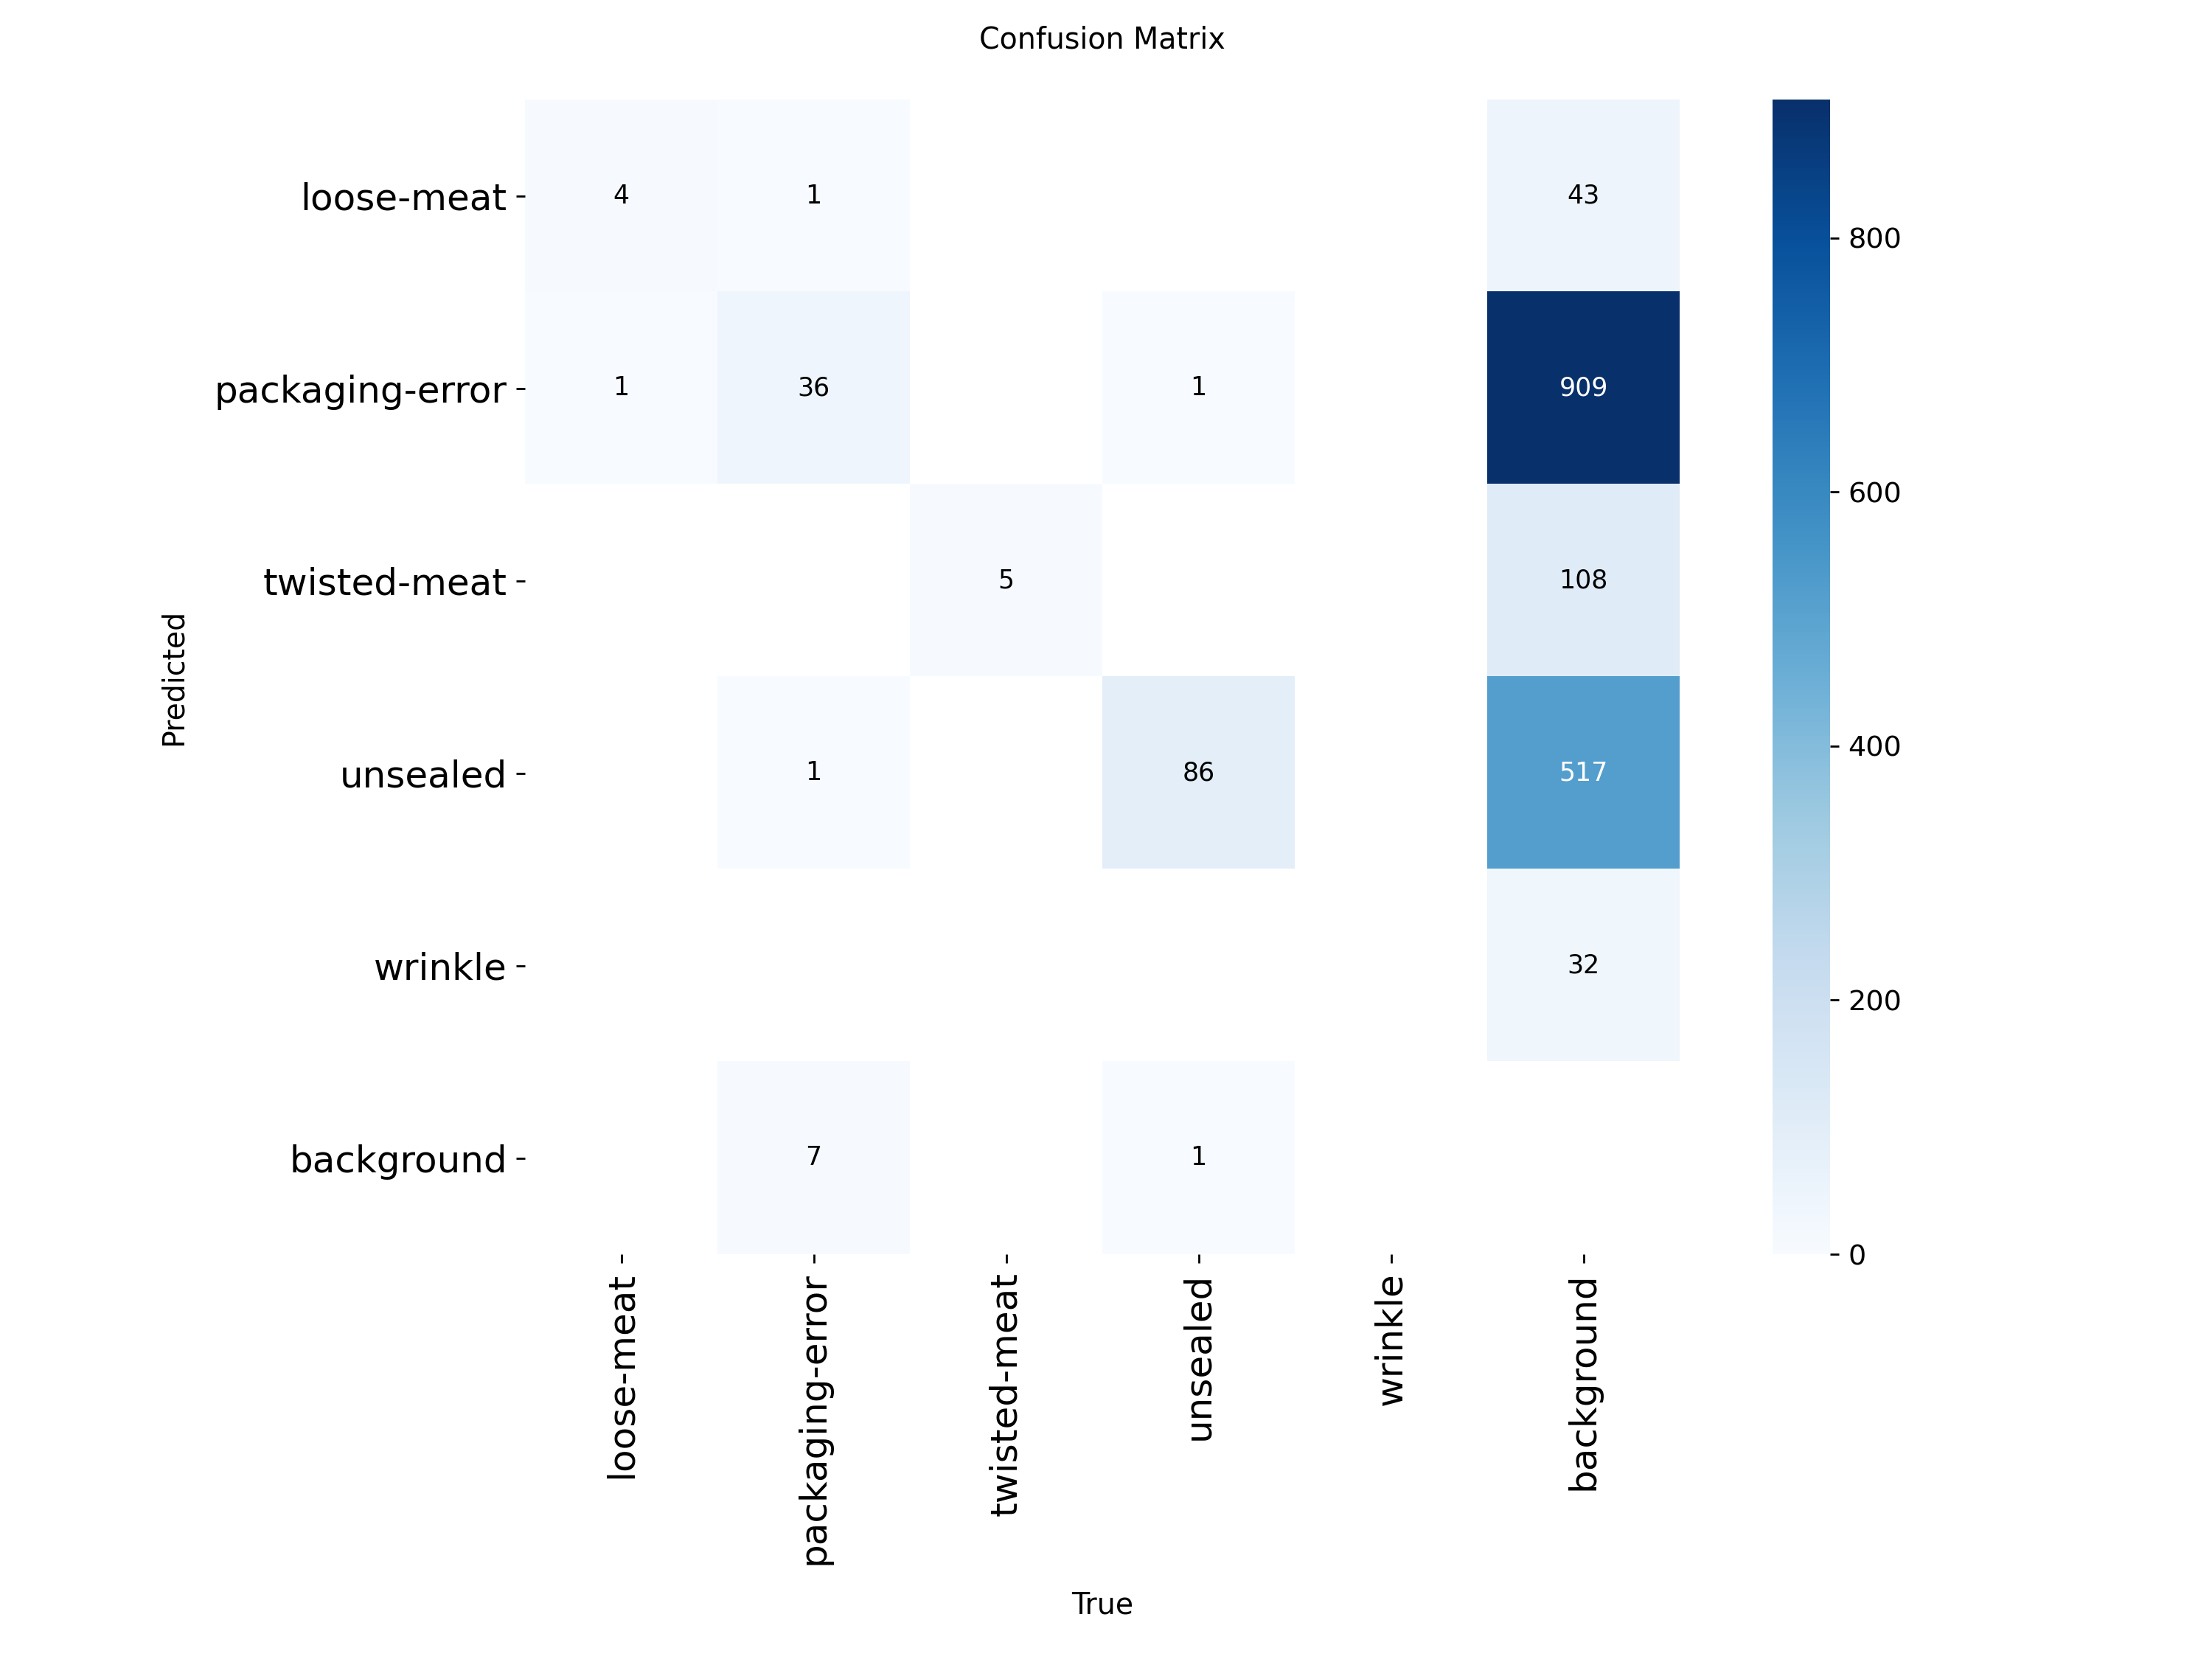


Validation images found: 115
Results saved to /content/drive/MyDrive/MMA3001_Project/runs/pork_error_analysis/predictions

Annotated predictions saved to:
/content/drive/MyDrive/MMA3001_Project/runs/pork_error_analysis/predictions

 frame_with_red_1122_jpg.rf.690c6a79cacd4c486cc47d0c27b50283.jpg


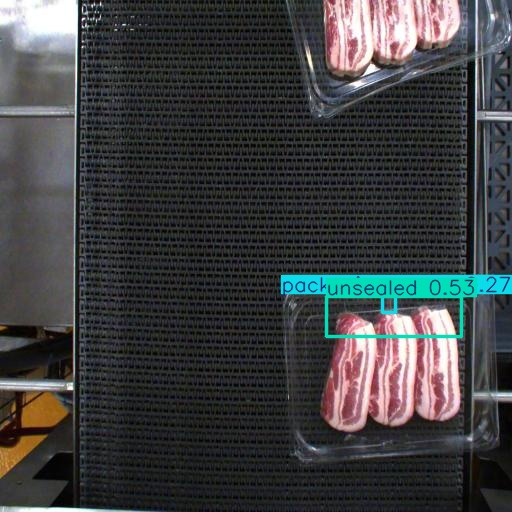


 frame_with_red_1126_jpg.rf.0d7b640b2e2be53b6d2cb4c9190f833f.jpg


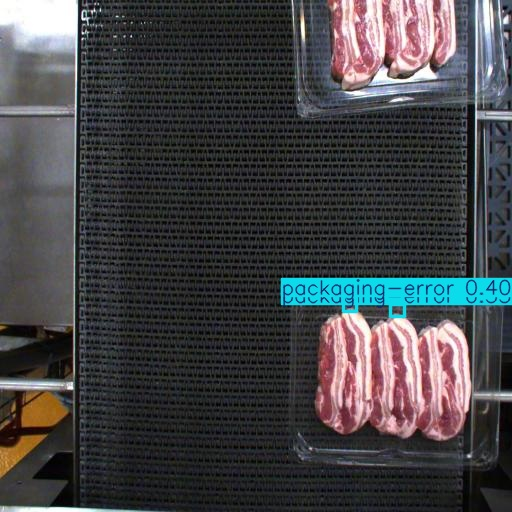


 frame_with_red_1134_jpg.rf.978c739ebc6f52eeffd557cdeff1d7d3.jpg


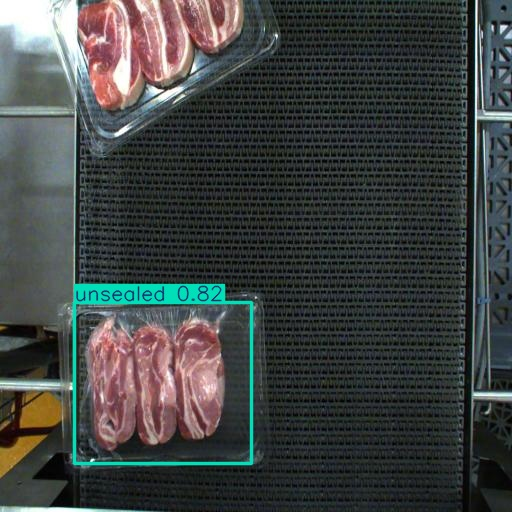


 frame_with_red_1177_jpg.rf.1ffd9c0412e4aa2042af32aac3ae0156.jpg


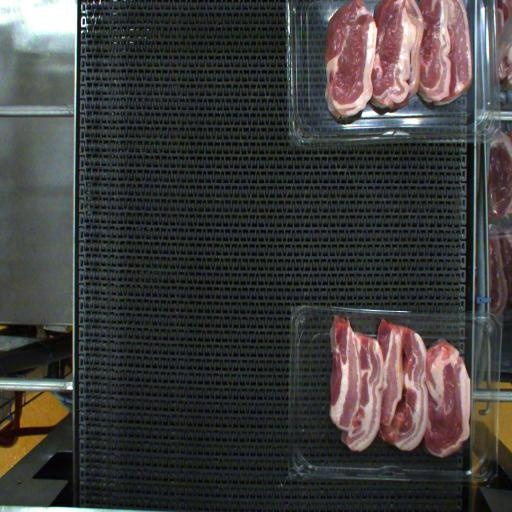


 frame_with_red_1195_jpg.rf.939f6279b0893f53067bd448cb906440.jpg


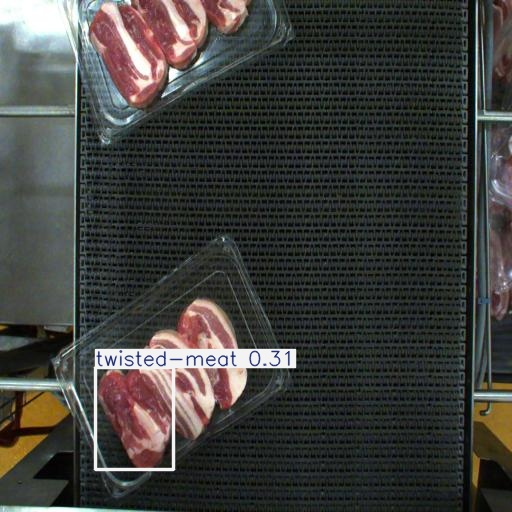


 frame_with_red_1223_jpg.rf.fed6330dd6b43d7f77b060f284346374.jpg


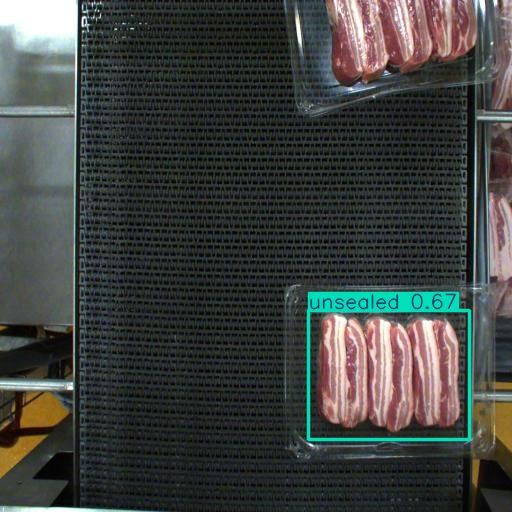

In [45]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image
import matplotlib.pyplot as plt
import pandas as pd

# --------------------------------------------------
# 1. Load optimised YOLOv8n model
# --------------------------------------------------

model_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001/weights/best.pt"
)

model = YOLO(model_path)

# --------------------------------------------------
# 2. Set output directory
# --------------------------------------------------

output_dir = Path(
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_error_analysis"
)

output_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 3. Generate validation confusion matrix
# --------------------------------------------------

metrics = model.val(
    data="/content/pork_dataset/data.yaml",
    split="val",
    imgsz=800,
    batch=16,
    device=0,
    plots=True,
    project=str(output_dir),
    name="validation",
    exist_ok=True
)

print("\nVALIDATION METRICS")
print(f"Precision:  {metrics.box.mp:.4f}")
print(f"Recall:     {metrics.box.mr:.4f}")
print(f"mAP@50:     {metrics.box.map50:.4f}")
print(f"mAP@50-95:  {metrics.box.map:.4f}")

# --------------------------------------------------
# 4. Display confusion matrix
# --------------------------------------------------

validation_dir = output_dir / "validation"

confusion_matrix_path = (
    validation_dir / "confusion_matrix.png"
)

if confusion_matrix_path.exists():
    display(Image(filename=str(confusion_matrix_path)))
else:
    print("Confusion matrix image not found.")

# --------------------------------------------------
# 5. Generate annotated predictions
# --------------------------------------------------

image_dir = Path("/content/pork_dataset/valid/images")

if not image_dir.exists():
    image_dir = Path("/content/pork_dataset/val/images")

image_paths = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

assert len(image_paths) > 0, "No validation images found."

print(f"\nValidation images found: {len(image_paths)}")

# Use 20 images initially
sample_images = image_paths[:20]

predictions = model.predict(
    source=[str(p) for p in sample_images],
    imgsz=800,
    conf=0.25,
    iou=0.70,
    device=0,
    save=True,
    project=str(output_dir),
    name="predictions",
    exist_ok=True,
    verbose=False
)

print("\nAnnotated predictions saved to:")
print(output_dir / "predictions")

# --------------------------------------------------
# 6. Display first 6 prediction images
# --------------------------------------------------

prediction_dir = output_dir / "predictions"

saved_images = sorted([
    p for p in prediction_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
])

for image_path in saved_images[:6]:
    print("\n", image_path.name)
    display(Image(filename=str(image_path), width=550))

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2210.6±691.6 MB/s, size: 50.2 KB)
val: Scanning /content/pork_dataset/valid/labels.cache... 115 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 115/115 37.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 3.0it/s 2.6s
                   all        115        143      0.807      0.668      0.694      0.355
            loose-meat          5          5      0.813      0.879      0.829      0.441
       packaging-error         30         45      0.581      0.111      0.189     0.0651
          twisted-meat          4          5          1      0.941      0.995       0.47
              unsealed         85         88      0.834      0.741      0.764      0.444
Speed: 3.5ms preprocess, 3.1ms inference, 0.

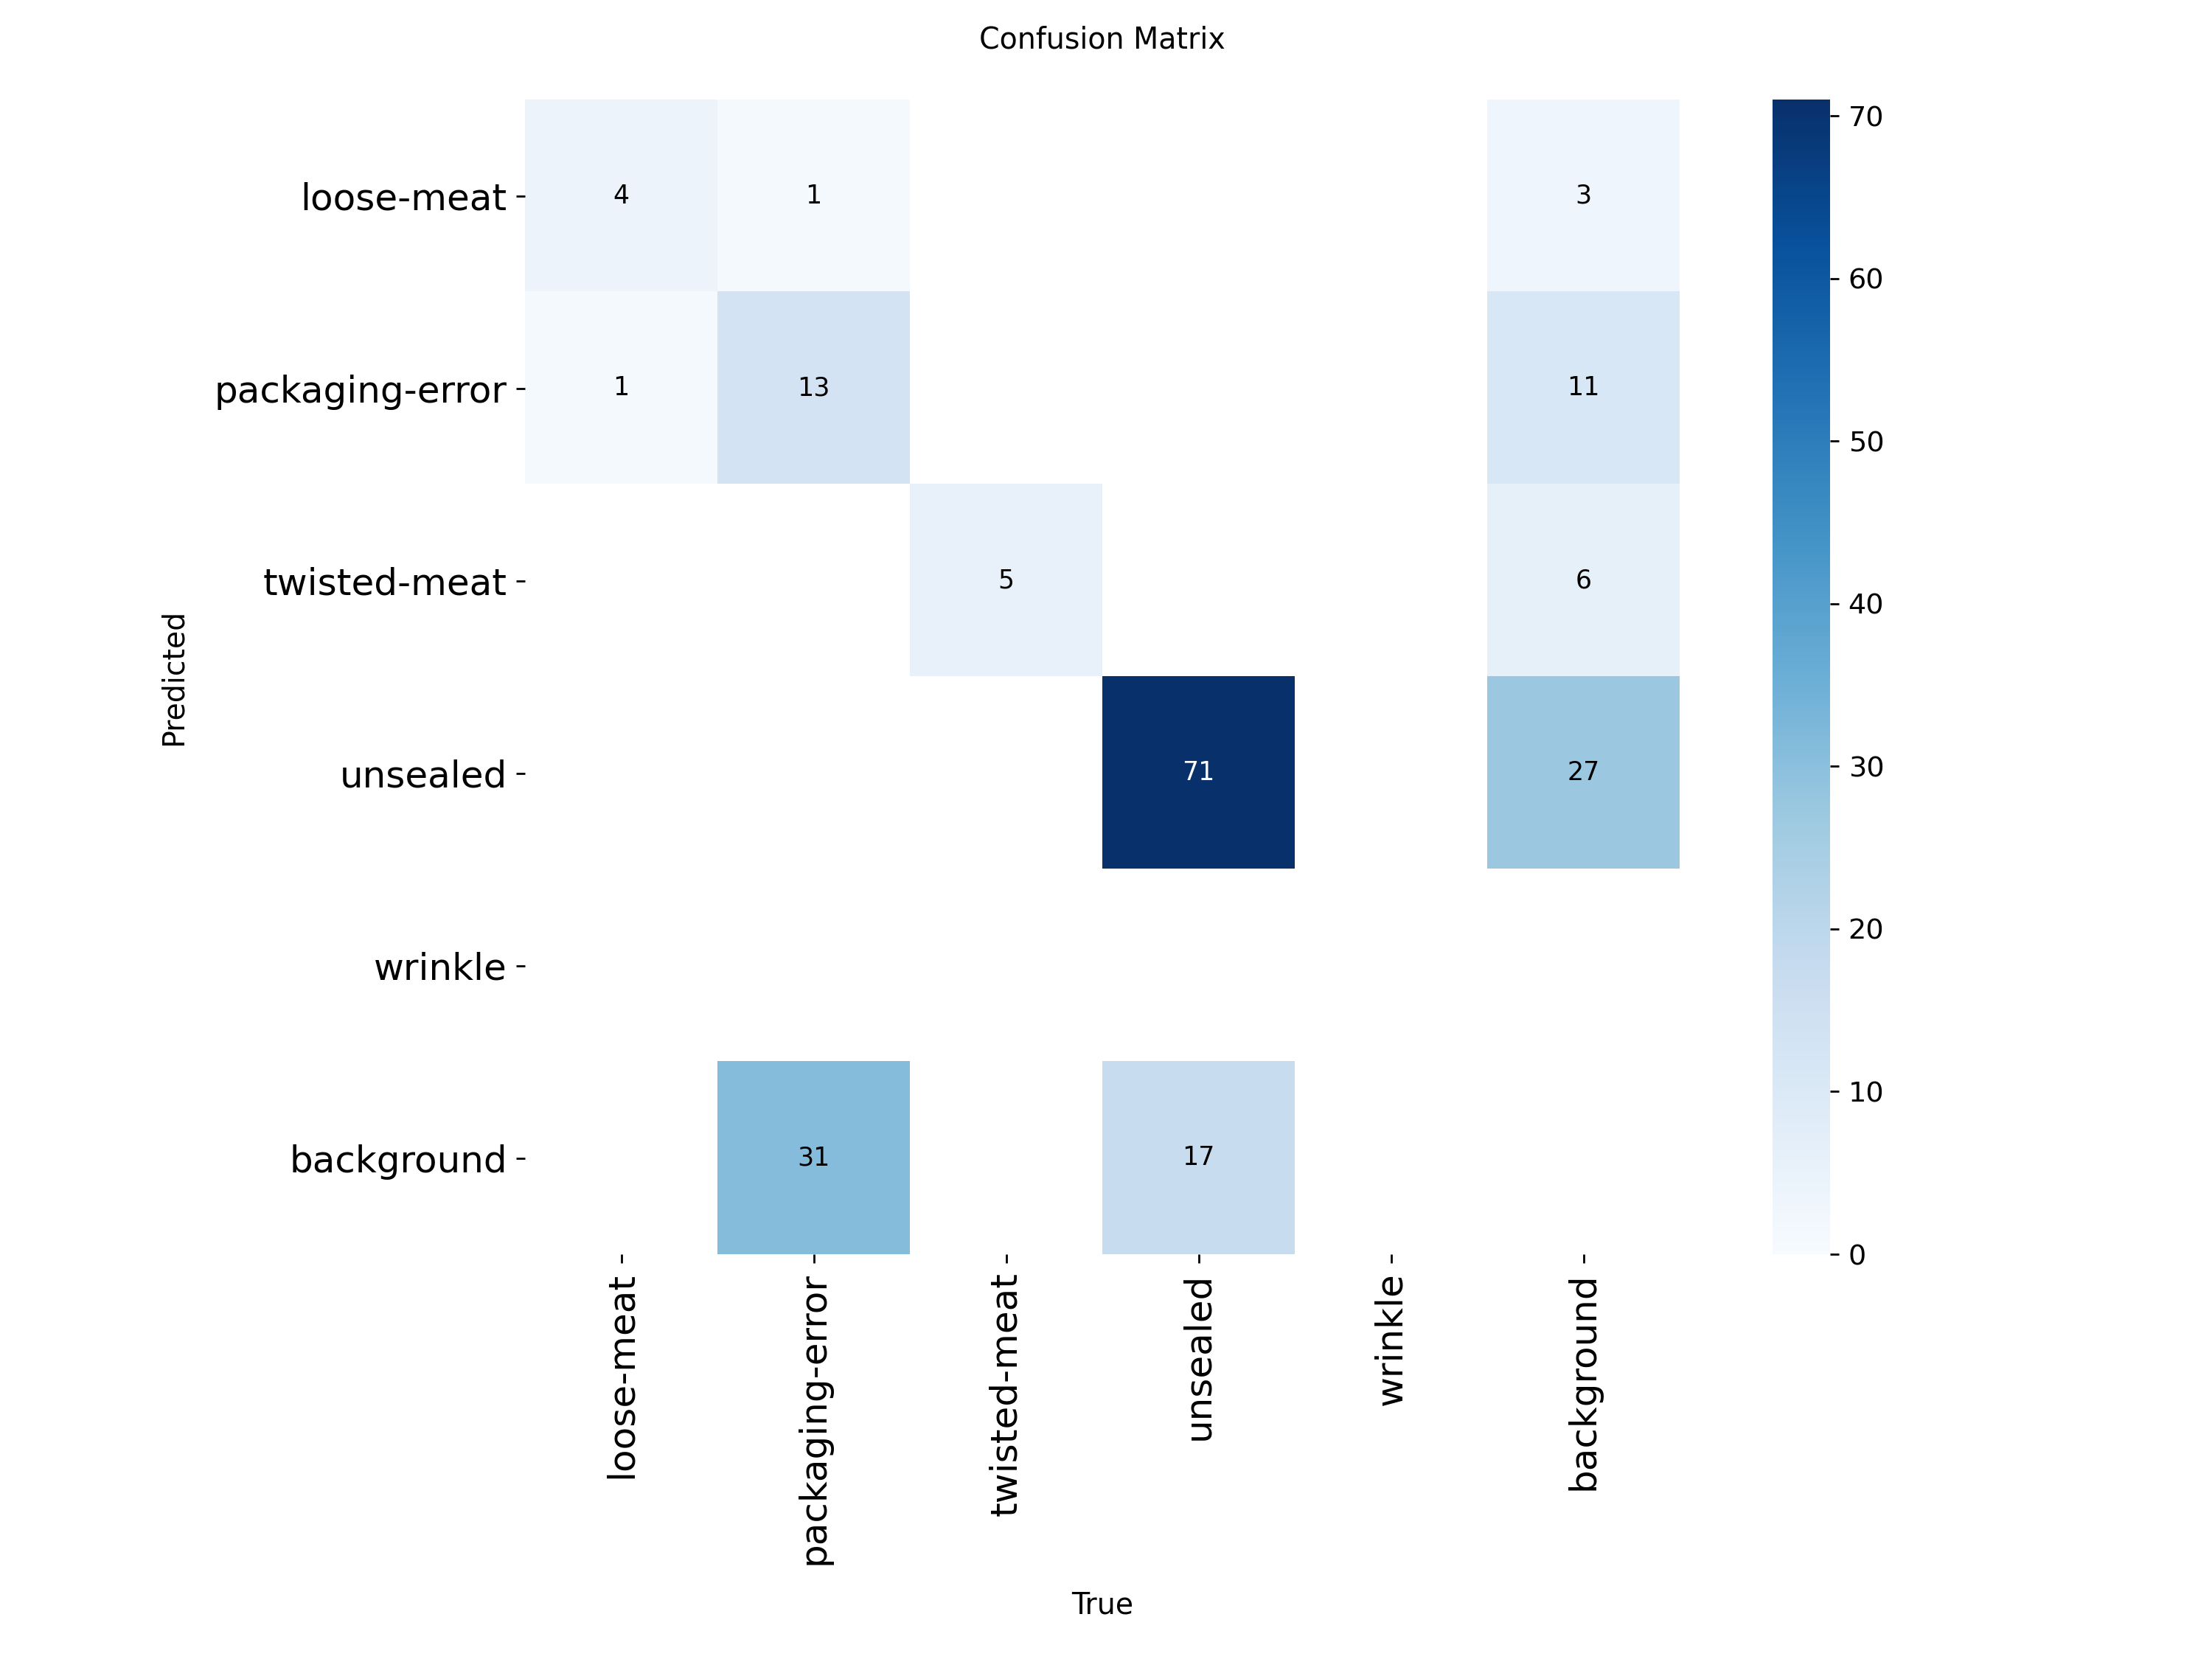

In [46]:
from ultralytics import YOLO
from pathlib import Path
from IPython.display import display, Image

model = YOLO(
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_lr_0_0001/weights/best.pt"
)

results = model.val(
    data="/content/pork_dataset/data.yaml",
    split="val",
    imgsz=800,
    batch=16,
    conf=0.25,
    iou=0.70,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/MMA3001_Project/runs/pork_error_analysis",
    name="validation_conf_025",
    exist_ok=True
)

print("\nValidation metrics at confidence threshold 0.25:")
print(f"Precision: {results.box.mp:.4f}")
print(f"Recall: {results.box.mr:.4f}")

matrix_path = Path(
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_error_analysis/"
    "validation_conf_025/confusion_matrix.png"
)

display(Image(filename=str(matrix_path)))

In [47]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Locate original baseline checkpoint
# --------------------------------------------------

drive_root = Path("/content/drive/MyDrive/MMA3001_Project")

possible_paths = [
    drive_root / "runs/pork_baseline/weights/best.pt",
    Path("/content/runs/pork_baseline/weights/best.pt"),
]

baseline_path = next(
    (p for p in possible_paths if p.exists()),
    None
)

if baseline_path is None:
    print("Baseline checkpoint not found in expected locations.")
    print("\nAvailable checkpoints:")

    for p in drive_root.rglob("best.pt"):
        print(p)

    raise FileNotFoundError(
        "Locate your original pork_baseline checkpoint "
        "and update baseline_path."
    )

print("Baseline checkpoint:", baseline_path)

# --------------------------------------------------
# 2. Load baseline model
# --------------------------------------------------

model = YOLO(str(baseline_path))

# --------------------------------------------------
# 3. Evaluate on TEST dataset
# --------------------------------------------------

results = model.val(
    data="/content/pork_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project=str(drive_root / "runs"),
    name="pork_baseline_test",
    exist_ok=True
)

# --------------------------------------------------
# 4. Display overall test metrics
# --------------------------------------------------

print("\n" + "=" * 55)
print("ORIGINAL BASELINE MODEL — TEST RESULTS")
print("=" * 55)

print(f"Precision:    {results.box.mp:.4f}")
print(f"Recall:       {results.box.mr:.4f}")
print(f"mAP@50:       {results.box.map50:.4f}")
print(f"mAP@50-95:    {results.box.map:.4f}")

# --------------------------------------------------
# 5. Display per-class performance
# --------------------------------------------------

class_results = []

for index, class_id in enumerate(results.box.ap_class_index):

    precision, recall, ap50, ap5095 = results.box.class_result(index)

    class_results.append({
        "Class": model.names[int(class_id)],
        "Precision": precision,
        "Recall": recall,
        "mAP@50": ap50,
        "mAP@50-95": ap5095
    })

df = pd.DataFrame(class_results)

print("\nPER-CLASS PERFORMANCE")
display(df)

# --------------------------------------------------
# 6. Save per-class metrics
# --------------------------------------------------

output_path = (
    drive_root / "runs/pork_baseline_test/per_class_metrics.csv"
)

df.to_csv(output_path, index=False)

print("\nResults saved to:", output_path.parent)

Baseline checkpoint not found in expected locations.

Available checkpoints:
/content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0003/weights/best.pt
/content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_0001/weights/best.pt
/content/drive/MyDrive/MMA3001_Project/runs/pork_lr_0_001/weights/best.pt


FileNotFoundError: Locate your original pork_baseline checkpoint and update baseline_path.

In [48]:
from pathlib import Path

search_dirs = [
    Path("/content/runs"),
    Path("/content/drive/MyDrive/MMA3001_Project"),
    Path("/content/drive/MyDrive")
]

for directory in search_dirs:
    print(f"\nSearching: {directory}")

    if directory.exists():
        matches = [
            p for p in directory.rglob("best.pt")
            if "baseline" in str(p).lower()
        ]

        if matches:
            for p in matches:
                print("FOUND:", p)
        else:
            print("No baseline checkpoint found.")


Searching: /content/runs
No baseline checkpoint found.

Searching: /content/drive/MyDrive/MMA3001_Project
No baseline checkpoint found.

Searching: /content/drive/MyDrive
No baseline checkpoint found.


In [50]:
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

# 1. Load recreated baseline model
baseline_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_baseline/weights/best.pt"
)

assert Path(baseline_path).exists(), "Baseline checkpoint not found."

baseline_model = YOLO(baseline_path)

# 2. Evaluate baseline on the test dataset
baseline_results = baseline_model.val(
    data="/content/pork_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/MMA3001_Project/runs",
    name="pork_baseline_test",
    exist_ok=True
)

# 3. Display overall metrics
print("\n" + "=" * 50)
print("BASELINE MODEL — TEST RESULTS")
print("=" * 50)

print(f"Precision:   {baseline_results.box.mp:.4f}")
print(f"Recall:      {baseline_results.box.mr:.4f}")
print(f"mAP@50:      {baseline_results.box.map50:.4f}")
print(f"mAP@50-95:   {baseline_results.box.map:.4f}")

# 4. Display per-class metrics
class_results = []

for index, class_id in enumerate(baseline_results.box.ap_class_index):
    precision, recall, ap50, ap5095 = baseline_results.box.class_result(index)

    class_results.append({
        "Class": baseline_model.names[int(class_id)],
        "Precision": precision,
        "Recall": recall,
        "mAP@50": ap50,
        "mAP@50-95": ap5095
    })

df = pd.DataFrame(class_results)

print("\nBASELINE PER-CLASS RESULTS")
display(df)

# 5. Save results
output_path = (
    "/content/drive/MyDrive/MMA3001_Project/"
    "runs/pork_baseline_test/per_class_metrics.csv"
)

df.to_csv(output_path, index=False)

print("\nResults saved to:", output_path)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2013.1±503.8 MB/s, size: 50.7 KB)
val: Scanning /content/pork_dataset/test/labels.cache... 76 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 76/76 26.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.8it/s 1.8s
                   all         76         91      0.454       0.66      0.598      0.254
            loose-meat          2          3      0.566          1       0.83      0.293
       packaging-error         22         29      0.338      0.282      0.296     0.0785
          twisted-meat          7          7      0.369      0.571      0.494      0.204
              unsealed         51         52      0.541      0.788      0.771      0.441
Speed: 3.1ms preprocess, 1.8ms inference, 0.0ms 

,Class,Precision,Recall,mAP@50,mAP@50-95
0,loose-meat,0.566375,1.000000,0.830000,0.292800
1,packaging-error,0.337903,0.281771,0.296456,0.078511
2,twisted-meat,0.369056,0.571429,0.494000,0.204314
3,unsealed,0.541106,0.788462,0.770649,0.441490



Results saved to: /content/drive/MyDrive/MMA3001_Project/runs/pork_baseline_test/per_class_metrics.csv
